In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('heart_disease_uci.csv')

In [3]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [4]:
df.shape

(920, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


### Data cleaning

In [6]:
# Remove unnecessary ID column
df = df.drop(columns=['id'], errors='ignore')

In [7]:
df.isnull().sum()

,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55
exang,55


In [8]:
# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())


In [9]:
# Fill missing categorical values with mode
for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

/tmp/ipykernel_5760/2234632329.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(df[col].mode()[0])


In [10]:
df.isnull().sum()

,0
age,0
sex,0
dataset,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


### Convert the target into binary classes

In [11]:
# 0 = No heart disease
# 1, 2, 3, 4 = Heart disease

df['num'] = (df['num'] > 0).astype(int)

print(df['num'].value_counts())

num
1    509
0    411
Name: count, dtype: int64


### Select features and target

In [12]:
X = df.drop(columns=['num'])
y = df['num']

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

### Split the dataset

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Feature scaling

In [15]:
from sklearn.preprocessing import StandardScaler

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

###Train Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression

In [18]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [19]:
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

###Train Decision Tree

In [20]:
from sklearn.tree import DecisionTreeClassifier

In [21]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [22]:
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

###Evaluate both models

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [24]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, dt_pred, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, dt_pred, zero_division=0)
    ]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.837,0.827,0.892
1,Decision Tree,0.783,0.804,0.804


###Plot confusion matrices

In [25]:
from sklearn.metrics import confusion_matrix

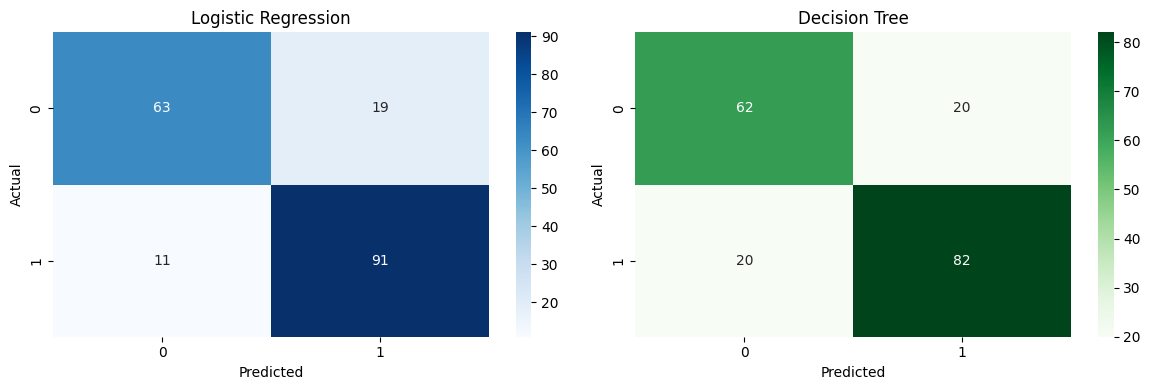

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(
    confusion_matrix(y_test, lr_pred),
    annot=True, fmt='d', cmap='Blues', ax=axes[0]
)
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(
    confusion_matrix(y_test, dt_pred),
    annot=True, fmt='d', cmap='Greens', ax=axes[1]
)
axes[1].set_title('Decision Tree')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

###Plot ROC curves

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

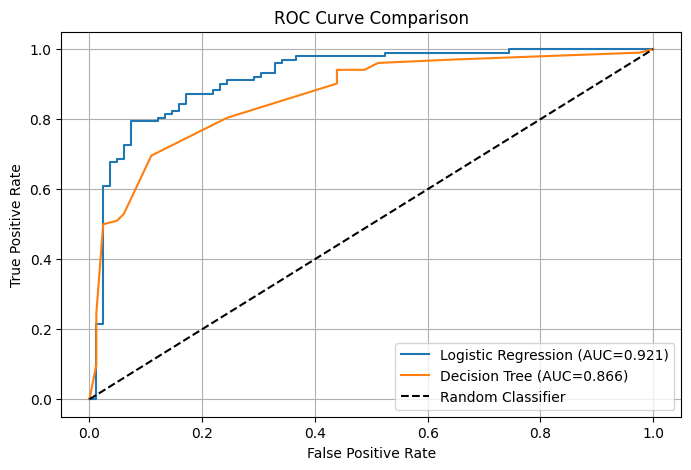

In [28]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_prob)

auc_lr = roc_auc_score(y_test, lr_prob)
auc_dt = roc_auc_score(y_test, dt_prob)

plt.figure(figsize=(8, 5))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={auc_lr:.3f})')
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC={auc_dt:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

###Compare the models

In [29]:
print("Logistic Regression AUC:", round(auc_lr, 3))
print("Decision Tree AUC:", round(auc_dt, 3))

best_model = results.loc[results['Accuracy'].idxmax(), 'Model']
print("Best model based on accuracy:", best_model)

Logistic Regression AUC: 0.921
Decision Tree AUC: 0.866
Best model based on accuracy: Logistic Regression


# Practice Que

### 1. Use cross_val_score to test accuracy

In [31]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [32]:
# Create model with feature scaling
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [33]:
# Perform 5-fold cross-validation
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

In [34]:
print("Cross-validation scores:", scores)
print("Average accuracy:", scores.mean())
print("Average accuracy percentage:", scores.mean() * 100, "%")

Cross-validation scores: [0.86486486 0.83673469 0.79591837 0.80272109 0.84353741]
Average accuracy: 0.8287552858981432
Average accuracy percentage: 82.87552858981432 %


### 2. Implement GridSearchCV for SVM

In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

In [38]:
# Create an SVM pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(probability=True, random_state=42))
])

In [39]:
# Define parameters to test
param_grid = {
    'svm__C': [0.1, 1, 10],
    'svm__kernel': ['linear', 'rbf'],
    'svm__gamma': ['scale', 'auto']
}

In [41]:
# Apply GridSearchCV
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm',
                                        SVC(probability=True,
                                            random_state=42))]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10],
                         'svm__gamma': ['scale', 'auto'],
                         'svm__kernel': ['linear', 'rbf']},
             scoring='accuracy')

In [42]:
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

Best parameters: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best cross-validation accuracy: 0.8301342158485016


Evaluate the best SVM model on test data

In [43]:
best_svm = grid_search.best_estimator_

svm_predictions = best_svm.predict(X_test)

In [44]:
print("Test Accuracy:", accuracy_score(y_test, svm_predictions))
print("Test Precision:", precision_score(y_test, svm_predictions, zero_division=0))
print("Test Recall:", recall_score(y_test, svm_predictions, zero_division=0))

Test Accuracy: 0.8532608695652174
Test Precision: 0.8260869565217391
Test Recall: 0.9313725490196079


### 4. Save the trained model using joblib

In [45]:
import joblib

# Save the trained model
joblib.dump(best_svm, 'heart_disease_model.pkl')

print("Model saved successfully!")

Model saved successfully!


### 4. Load the model and predict on new data

In [46]:
import joblib

loaded_model = joblib.load('heart_disease_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


Make a prediction

In [47]:
# Select one example with the correct feature columns
new_patient = X_test.iloc[[0]]

In [48]:
# Predict using the loaded model
prediction = loaded_model.predict(new_patient)[0]

print("Prediction:", prediction)

if prediction == 1:
    print("Predicted class: Heart disease")
else:
    print("Predicted class: No heart disease")

Prediction: 0
Predicted class: No heart disease
